# Stream Data Sampling and Filtering Using Python

**Mapped CO:** CO3  
**Aim:** To implement sampling and filtering techniques for processing continuous data streams efficiently using Python.

## Objectives
- Understand the concept of data streams.
- Perform random sampling on streaming data.
- Filter stream values using a specified condition.
- Compare the original, sampled, and filtered data.
- Observe how sample size and stream size affect the results.

## Theory
A **data stream** is a continuous sequence of data items arriving over time. Examples include sensor readings, network traffic, online transactions, and social-media events.

**Sampling** selects a subset of items from a stream. It can reduce the amount of data that must be stored or processed.

**Filtering** checks each item against a condition and retains only the items that satisfy it. For example, a sensor-monitoring application may retain only readings greater than a chosen threshold.

> In this practical, a finite list of generated values represents a short section (batch) of an incoming stream. The same operations can be applied repeatedly as new batches arrive.


## 1. Import required libraries

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reproducibility: the same random values and sample are produced on each run.
random.seed(42)
np.random.seed(42)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Generate a simulated data stream

Each incoming item is represented by a numeric value between 0 and 100. The generator below yields values one at a time, like a simple stream source. We collect a finite batch for this experiment.

In [2]:
def generate_data_stream(number_of_items=30, low=0, high=100):
    """Yield number_of_items simulated numeric readings, one at a time."""
    for _ in range(number_of_items):
        yield random.randint(low, high)


# Collect one finite batch from the simulated stream.
stream_size = 30
data_stream = list(generate_data_stream(stream_size))

print(f"Stream generated successfully: {len(data_stream)} values")
print(data_stream)

Stream generated successfully: 30 values
[81, 14, 3, 94, 35, 31, 28, 17, 94, 13, 86, 94, 69, 11, 75, 54, 4, 3, 11, 27, 29, 64, 77, 3, 71, 25, 91, 83, 89, 69]


## 3. Display the original stream

In [3]:
original_df = pd.DataFrame({
    "Item Number": range(1, len(data_stream) + 1),
    "Value": data_stream
})

display(original_df)

print("Number of values in original stream:", len(data_stream))
print("Minimum value:", min(data_stream))
print("Maximum value:", max(data_stream))
print("Average value:", round(np.mean(data_stream), 2))

,Item Number,Value
0,1,81
1,2,14
2,3,3
3,4,94
4,5,35
5,6,31
6,7,28
7,8,17
8,9,94
9,10,13


Number of values in original stream: 30
Minimum value: 3
Maximum value: 94
Average value: 48.17


## 4. Apply random sampling

Random sampling selects a fixed number of distinct items from the collected stream. Here, `random.sample()` samples **without replacement**, so an item cannot be selected more than once.

Change `sample_size` to observe how the selected subset changes.

In [4]:
sample_size = 10  # Try values such as 5, 15, or 20.

if not 0 <= sample_size <= len(data_stream):
    raise ValueError("sample_size must be between 0 and the stream size.")

sampled_data = random.sample(data_stream, sample_size)

sampled_df = pd.DataFrame({
    "Sample Number": range(1, len(sampled_data) + 1),
    "Value": sampled_data
})

print(f"Sampled {len(sampled_data)} values from {len(data_stream)} original values:")
display(sampled_df)

Sampled 10 values from 30 original values:


,Sample Number,Value
0,1,11
1,2,17
2,3,75
3,4,11
4,5,94
5,6,81
6,7,31
7,8,77
8,9,69
9,10,86


## 5. Filter the sampled data

Filtering retains only those sampled values that meet a condition. In the first example, we keep values **greater than 50**.

Sampling and filtering are different operations:
- Sampling chooses a subset, usually without checking the value against a threshold.
- Filtering checks a condition and keeps every item in the input that satisfies it.

In [5]:
threshold = 50

filtered_data = [value for value in sampled_data if value > threshold]

filtered_df = pd.DataFrame({
    "Filtered Item": range(1, len(filtered_data) + 1),
    "Value": filtered_data
})

print(f"Values greater than {threshold} in the sampled data:")
display(filtered_df)

print(f"Sampled values: {len(sampled_data)}")
print(f"Filtered values: {len(filtered_data)}")

Values greater than 50 in the sampled data:


,Filtered Item,Value
0,1,75
1,2,94
2,3,81
3,4,77
4,5,69
5,6,86


Sampled values: 10
Filtered values: 6


## 6. Compare original, sampled, and filtered data

,Stage,Number of values
0,Original stream,30
1,Sampled data,10
2,Filtered data,6


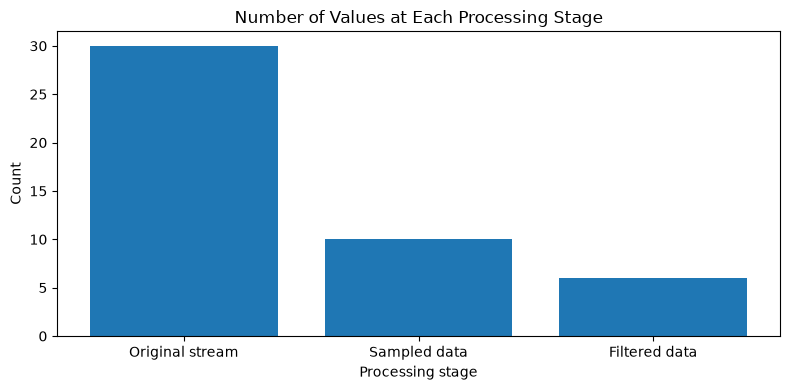

In [6]:
comparison = pd.DataFrame({
    "Stage": ["Original stream", "Sampled data", "Filtered data"],
    "Number of values": [
        len(data_stream),
        len(sampled_data),
        len(filtered_data)
    ]
})

display(comparison)

plt.figure(figsize=(8, 4))
plt.bar(comparison["Stage"], comparison["Number of values"])
plt.title("Number of Values at Each Processing Stage")
plt.ylabel("Count")
plt.xlabel("Processing stage")
plt.tight_layout()
plt.show()

## 7. Visualize the values

The plots show the original stream, the random sample, and the values that remain after filtering.

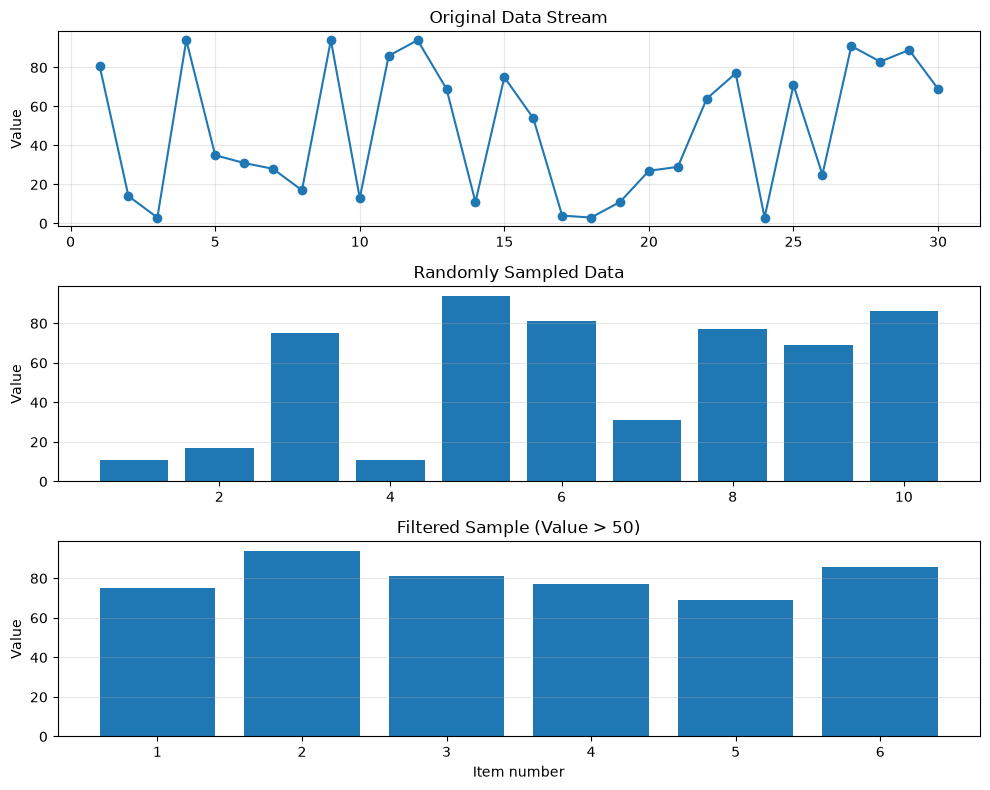

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8))

axes[0].plot(range(1, len(data_stream) + 1), data_stream, marker="o")
axes[0].set_title("Original Data Stream")
axes[0].set_ylabel("Value")
axes[0].grid(True, alpha=0.3)

axes[1].bar(range(1, len(sampled_data) + 1), sampled_data)
axes[1].set_title("Randomly Sampled Data")
axes[1].set_ylabel("Value")
axes[1].grid(axis="y", alpha=0.3)

axes[2].bar(range(1, len(filtered_data) + 1), filtered_data)
axes[2].set_title(f"Filtered Sample (Value > {threshold})")
axes[2].set_xlabel("Item number")
axes[2].set_ylabel("Value")
axes[2].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Experiment: change the sample size

A larger sample generally includes more of the original stream, while a smaller sample reduces the number of values that need to be examined. Run this cell with different sample sizes.

The sample is taken from the original stream each time.

In [8]:
sample_sizes = [5, 10, 20]

sample_size_results = []

for size in sample_sizes:
    if size > len(data_stream):
        continue

    current_sample = random.sample(data_stream, size)
    current_filtered = [x for x in current_sample if x > threshold]

    sample_size_results.append({
        "Sample size": size,
        "Filtered count (> 50)": len(current_filtered),
        "Filtered percentage of sample": round(
            (len(current_filtered) / size) * 100, 2
        ) if size else 0
    })

display(pd.DataFrame(sample_size_results))

,Sample size,Filtered count (> 50),Filtered percentage of sample
0,5,3,60.0
1,10,6,60.0
2,20,9,45.0


## 9. Exercise: filter values greater than 80

This cell repeats the filtering step with a threshold of 80 instead of 50.

In [9]:
threshold_80 = 80

filtered_above_80 = [value for value in sampled_data if value > threshold_80]

print(f"Sampled values: {sampled_data}")
print(f"Values greater than {threshold_80}: {filtered_above_80}")
print("Count:", len(filtered_above_80))

Sampled values: [11, 17, 75, 11, 94, 81, 31, 77, 69, 86]
Values greater than 80: [94, 81, 86]
Count: 3


## 10. Exercise: generate a larger data stream

Generate 1,000 readings, take a random sample, and filter the sample. Compare the sizes before and after each operation.

In [10]:
large_stream_size = 1000
large_stream = list(generate_data_stream(large_stream_size))

large_sample_size = 100
large_sample = random.sample(large_stream, large_sample_size)
large_filtered = [value for value in large_sample if value > 80]

large_results = pd.DataFrame({
    "Stage": ["Large original stream", "Large random sample", "Sample values > 80"],
    "Count": [len(large_stream), len(large_sample), len(large_filtered)]
})

display(large_results)

print("First 20 values in large stream:", large_stream[:20])
print("First 20 values in large sample:", large_sample[:20])
print("Filtered values (> 80):", large_filtered)

,Stage,Count
0,Large original stream,1000
1,Large random sample,100
2,Sample values > 80,16


First 20 values in large stream: [35, 58, 81, 46, 20, 47, 45, 26, 85, 34, 89, 87, 82, 9, 77, 81, 21, 68, 93, 31]
First 20 values in large sample: [62, 73, 32, 39, 96, 75, 42, 76, 97, 81, 31, 35, 16, 31, 55, 51, 29, 56, 8, 41]
Filtered values (> 80): [96, 97, 81, 89, 83, 100, 84, 85, 81, 99, 86, 96, 98, 91, 91, 86]


## 11. Exercise: apply sampling and filtering to another dataset

For demonstration, create a small table of simulated IoT temperature readings. Sample some readings and then retain readings above 30°C.

This illustrates how the same methods can be used with application-specific data.

In [11]:
iot_data = pd.DataFrame({
    "Sensor": [f"S{i:02d}" for i in range(1, 21)],
    "Temperature_C": np.round(np.random.uniform(20, 40, 20), 2)
})

print("Original IoT readings:")
display(iot_data)

iot_sample = iot_data.sample(n=8, random_state=42)
iot_filtered = iot_sample[iot_sample["Temperature_C"] > 30]

print("Random sample of 8 readings:")
display(iot_sample.reset_index(drop=True))

print("Sampled readings with temperature > 30°C:")
display(iot_filtered.reset_index(drop=True))

Original IoT readings:


,Sensor,Temperature_C
0,S01,27.49
1,S02,39.01
2,S03,34.64
3,S04,31.97
4,S05,23.12
5,S06,23.12
6,S07,21.16
7,S08,37.32
8,S09,32.02
9,S10,34.16


Random sample of 8 readings:


,Sensor,Temperature_C
0,S01,27.49
1,S18,30.50
2,S16,23.67
3,S02,39.01
4,S09,32.02
5,S06,23.12
6,S12,39.40
7,S04,31.97


Sampled readings with temperature > 30°C:


,Sensor,Temperature_C
0,S18,30.50
1,S02,39.01
2,S09,32.02
3,S12,39.40
4,S04,31.97


## 12. Assignment questions

### 1. Change the sample size and observe the output.
Changing `sample_size` changes how many items are selected from the original stream. A small sample processes fewer values, while a larger sample usually represents more of the stream. Because selection is random, the actual values can differ between runs unless a fixed random seed is used.

### 2. Filter values greater than 80 instead of 50.
Set `threshold = 80` and run the filtering cell again. Only sampled values strictly greater than 80 are retained.

### 3. Generate a larger data stream and compare the results.
The larger-stream experiment generates 1,000 values and samples 100 of them. The sample is smaller than the full stream, reducing the number of values used in the next processing stage. The exact number of values above 80 depends on the generated readings and the random sample.

### 4. Explain the difference between sampling and filtering.
**Sampling** selects a subset of records from the input, often randomly and without considering a condition on each value. **Filtering** examines records against a specified condition and retains only those that satisfy it. Sampling controls how many records are selected; filtering controls which records qualify.

### 5. Apply the same techniques to another dataset.
The IoT temperature example creates sensor readings, samples eight records, and then filters readings above 30°C. The same approach can be applied to traffic measurements, network packets, transaction values, or other numerical datasets.

## Result
Sampling and filtering were implemented successfully on a simulated data stream using Python. Random sampling selected a subset of values, and condition-based filtering retained only values meeting the chosen threshold.

## Conclusion
This experiment demonstrated two basic stream-processing operations. Sampling reduces the volume of data considered for analysis, while filtering extracts records relevant to a specified condition. Both techniques are useful in real-time applications such as sensor monitoring, network analysis, and transaction processing.